# Entender quien escribe mal: resultados

Antes de abrir este notebook hay que correr `uv run python experimento.py`, que genera `results/metrics.csv` y `results/predictions.parquet`.

## Nota metodológica: partición de los datos

MASSIVE es-ES viene con tres conjuntos: train (11.514 frases), validation (2.033) y test (2.974). Siguiendo la propuesta, usamos **train** para entrenar, **test** para elegir hiperparámetros y **validation** para medir el rendimiento sin ruido y la robustez, aplicando las perturbaciones sobre validation.

Es la convención inversa a la habitual (elegir con validation y evaluar con test). Es metodológicamente equivalente: lo importante es que el conjunto donde se mide la robustez no se haya usado para elegir hiperparámetros. Por eso el rendimiento sin ruido se reporta sobre validation y no sobre test, que está sesgado a favor de los modelos. (La propuesta menciona "test" en Métodos y "validación" en Dataset; aplicamos la segunda.)

Consecuencias: la robustez se mide con 2.033 frases y las cifras no son comparables con las del paper de MASSIVE. Validation tiene 59 intenciones (falta `audio_volume_other`), y seis de ellas tienen 5 frases o menos, por lo que su F1 es inestable.

**Confusión de base.** Sin ruido los modelos ya se equivocan entre el 13 y el 21 % de las frases, sobre todo en pares semánticamente cercanos (por ejemplo `qa_maths` con `qa_factoid` o `music_settings` con `play_music`), y `general_quirky` actúa como sumidero. Por eso medimos la **caída** respecto de la versión limpia de cada frase: a intensidad 0,25 en typos, entre el 52 y el 75 % de los errores ya existían sin ruido.

In [1]:
import pandas as pd

from tp import plots
from tp.data import RESULTS_DIR, SEED  # noqa: F401 (se usa como @SEED en query)
from tp.plots import MODEL_LABELS, PERTURBATION_LABELS

pd.set_option("display.precision", 3)
metrics = pd.read_csv(RESULTS_DIR / "metrics.csv")
predictions = pd.read_parquet(RESULTS_DIR / "predictions.parquet")
models = [m for m in MODEL_LABELS if m in set(metrics["model"])]
models

/home/max/Projects/2Q2026/nlp_tp_2026/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['tfidf_word', 'tfidf_char', 'fasttext_word', 'fasttext', 'beto']

## 1. Rendimiento sin ruido (validation)

Se reporta sobre validation porque los hiperparámetros se eligieron con test: el rendimiento en test está sesgado a favor de los modelos ajustados. La columna `f1_macro_test` se muestra solo como referencia.

In [2]:
from tp.evaluation import average_seeds

# Promedio de las semillas de entrenamiento; _std es el desvío entre ellas.
avg = average_seeds(metrics).query("perturbation == 'clean'")
cols = ["accuracy", "accuracy_std", "f1_macro", "f1_macro_std", "n_seeds"]
clean = avg.query("split == 'validation'").set_index("model").loc[models, cols]
clean["f1_macro_test"] = avg.query("split == 'test'").set_index("model")["f1_macro"]
clean.rename(index=MODEL_LABELS)

,accuracy,accuracy_std,f1_macro,f1_macro_std,n_seeds,f1_macro_test
model,,,,,,
TF-IDF palabras,0.813,NaN,0.780,NaN,1,0.782
TF-IDF caracteres,0.842,NaN,0.807,NaN,1,0.794
FastText sin subpalabras,0.789,9.838e-04,0.766,0.002,3,0.760
FastText con subpalabras,0.821,1.704e-03,0.795,0.002,3,0.787
BETO,0.872,3.821e-03,0.819,0.014,3,0.801


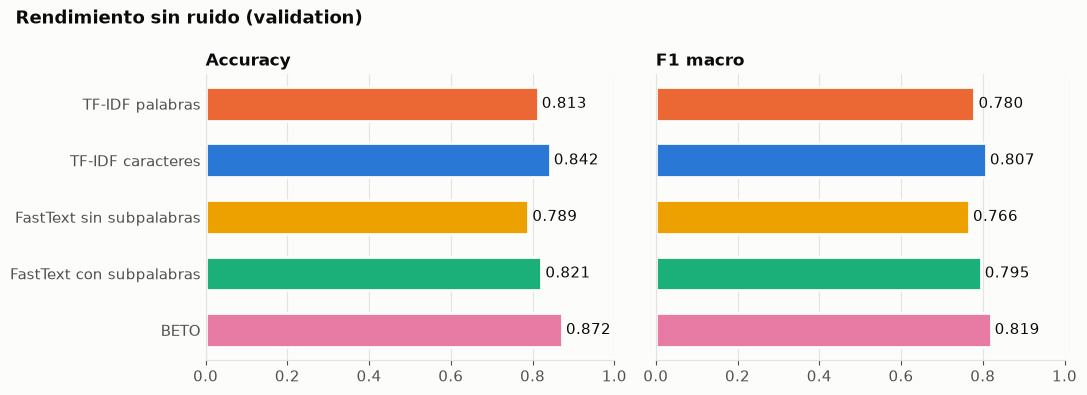

In [3]:
plots.plot_clean(metrics);

## 2. Ejemplos de cada perturbación

In [4]:
from tp.perturbations import PERTURBATIONS, perturb

ejemplos = predictions.query(
    "model == @models[0] and perturbation == 'clean' and split == 'validation'"
)["original"]
frases = ejemplos.sample(4, random_state=1).tolist()
pd.DataFrame(
    {PERTURBATION_LABELS[n]: perturb(frases, n, 0.5) for n in PERTURBATIONS},
    index=frases,
).T

,dime la hora,está mi alarma de la escuela puesta,pon una canción,que día es hoy
Sin tildes,dime la hora,esta mi alarma de la escuela puesta,pon una cancion,que dia es hoy
Minúsculas y sin puntuación,dime la hora,está mi alarma de la escuela puesta,pon una canción,que día es hoy
Errores de tipeo,dime la hora,está mi aiarma de la eescuela upesta,po unna acnción,qeu díx es moy
Abreviaturas,dime la hora,está mi alarma d la escuela puesta,pon una canción,que día es hoy
Voseo rioplatense,decime la hora,está mi alarma de la escuela puesta,poné una canción,que día es hoy
Vocabulario coloquial,dime la hora,está mi alarma de la escuela puesta,pon una canción,que día es hoy
Combinado,dime la hora,está mi xlarma de la escuela puesta,pon unaa cancion,qu dix es hoy


## 3. Degradación frente al ruido (validation)

Las curvas usan F1 macro. Las líneas punteadas son los modelos que ven palabras completas.

In [5]:
val = metrics[metrics["split"] == "validation"]
tabla = val.pivot_table(
    index=["perturbation", "intensity"], columns="model", values="f1_macro"
)[models]
tabla.rename(columns=MODEL_LABELS)

model                     TF-IDF palabras  TF-IDF caracteres  \
perturbation   intensity                                       
abbreviations  0.10                 0.778              0.807   
               0.25                 0.778              0.806   
               0.50                 0.772              0.805   
               0.75                 0.772              0.803   
               1.00                 0.771              0.798   
clean          0.00                 0.780              0.807   
colloquial     0.10                 0.777              0.805   
               0.25                 0.772              0.802   
               0.50                 0.764              0.795   
               0.75                 0.755              0.788   
               1.00                 0.745              0.778   
lower_no_punct 0.10                 0.780              0.808   
               0.25                 0.780              0.808   
               0.50                 0.780              0.808   
               0.75                 0.780              0.808   
               1.00                 0.780              0.808   
mixed          0.10                 0.723              0.790   
               0.25                 0.646              0.765   
               0.50                 0.488              0.694   
               0.75                 0.296              0.616   
               1.00                 0.059              0.530   
no_accents     0.10                 0.778              0.811   
               0.25                 0.775              0.812   
               0.50                 0.769              0.811   
               0.75                 0.763              0.810   
               1.00                 0.750              0.810   
typos          0.10                 0.741              0.799   
               0.25                 0.673              0.778   
               0.50                 0.546              0.730   
               0.75                 0.360              0.677   
               1.00                 0.074              0.619   
voseo          0.10                 0.774              0.804   
               0.25                 0.767              0.799   
               0.50                 0.757              0.794   
               0.75                 0.741              0.785   
               1.00                 0.727              0.776   

model                     FastText sin subpalabras  FastText con subpalabras  \
perturbation   intensity                                                       
abbreviations  0.10                          0.766                     0.794   
               0.25                          0.759                     0.794   
               0.50                          0.754                     0.797   
               0.75                          0.744                     0.793   
               1.00                          0.739                     0.795   
clean          0.00                          0.766                     0.795   
colloquial     0.10                          0.762                     0.792   
               0.25                          0.757                     0.790   
               0.50                          0.746                     0.783   
               0.75                          0.732                     0.776   
               1.00                          0.717                     0.767   
lower_no_punct 0.10                          0.766                     0.795   
               0.25                          0.766                     0.795   
               0.50                          0.766                     0.795   
               0.75                          0.766                     0.795   
               1.00                          0.766                     0.795   
mixed          0.10                          0.710                     0.764   
               0.25                          0.

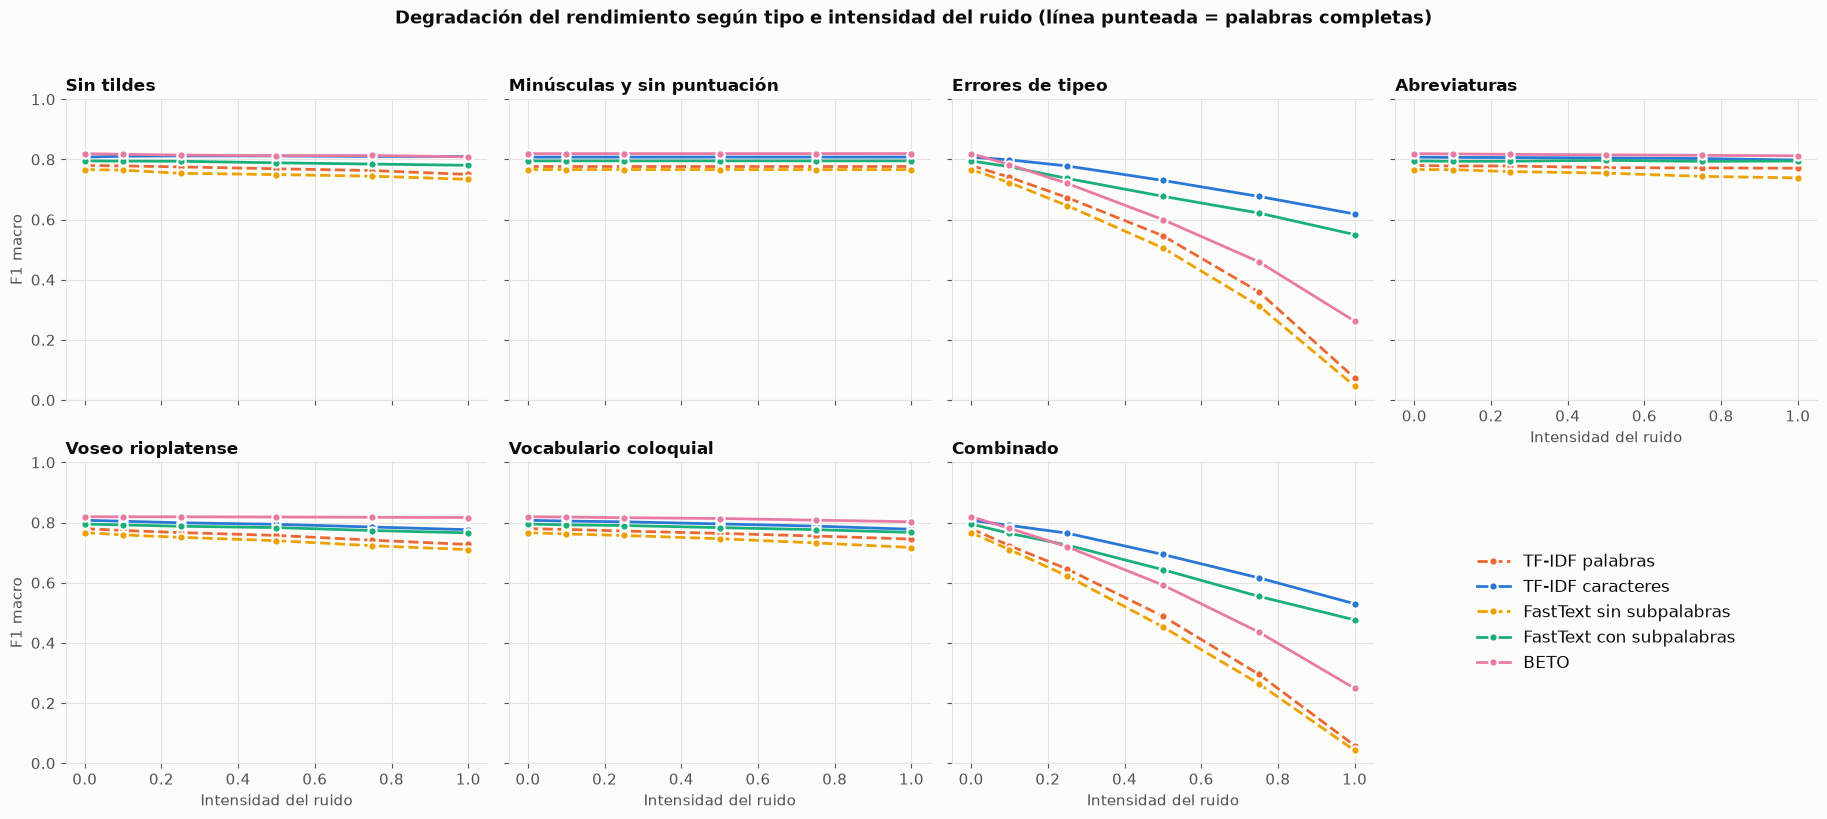

In [6]:
plots.plot_degradation(metrics);

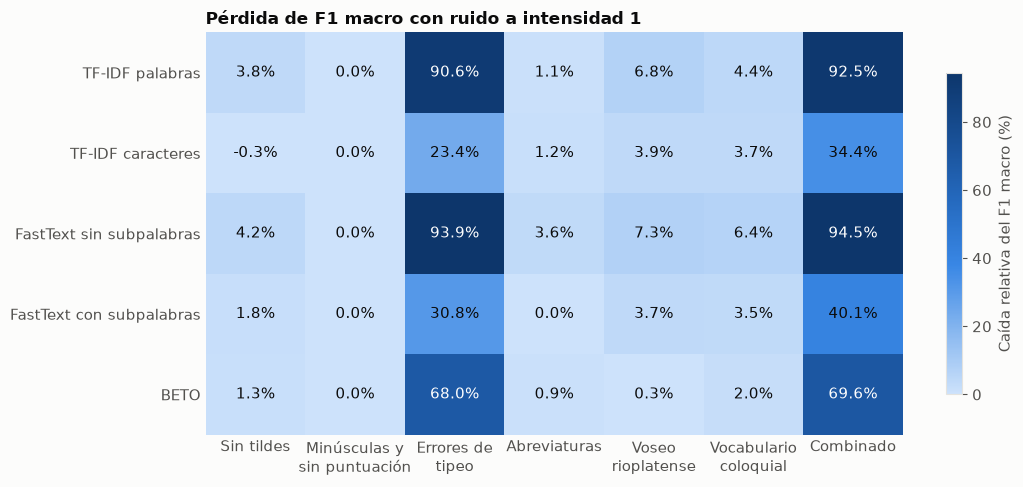

In [7]:
plots.plot_drop_heatmap(metrics, intensity=1.0);

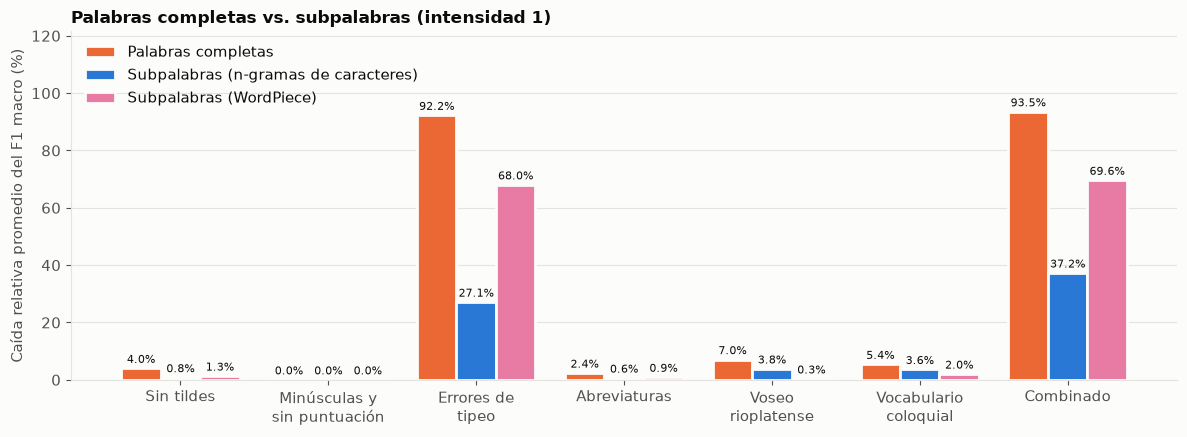

In [8]:
plots.plot_word_vs_subword(metrics, intensity=1.0);

### Caídas con intervalo de confianza

Diferencia de caídas de accuracy entre dos modelos (bootstrap pareado sobre frases, IC 95 %). Positiva: el primer modelo cae más. Si el intervalo no incluye 0, la diferencia no se explica por la muestra de frases. `fasttext_word` contra `fasttext` aísla el efecto de las subpalabras.

In [9]:
from tp.evaluation import compare_drops

compare_drops(predictions, "fasttext_word", "fasttext").query(
    "split == 'validation'"
).round(3)

,split,perturbation,intensity,drop_diff,ci_low,ci_high,n
0,validation,abbreviations,0.10,-0.001,-0.004,0.001,2033
1,validation,abbreviations,0.25,-0.002,-0.006,0.002,2033
2,validation,abbreviations,0.50,-0.001,-0.007,0.006,2033
3,validation,abbreviations,0.75,0.001,-0.007,0.010,2033
4,validation,abbreviations,1.00,0.002,-0.008,0.012,2033
5,validation,colloquial,0.10,0.002,0.001,0.004,2033
6,validation,colloquial,0.25,0.005,0.002,0.008,2033
7,validation,colloquial,0.50,0.010,0.004,0.016,2033
8,validation,colloquial,0.75,0.017,0.009,0.026,2033
9,validation,colloquial,1.00,0.023,0.013,0.034,2033


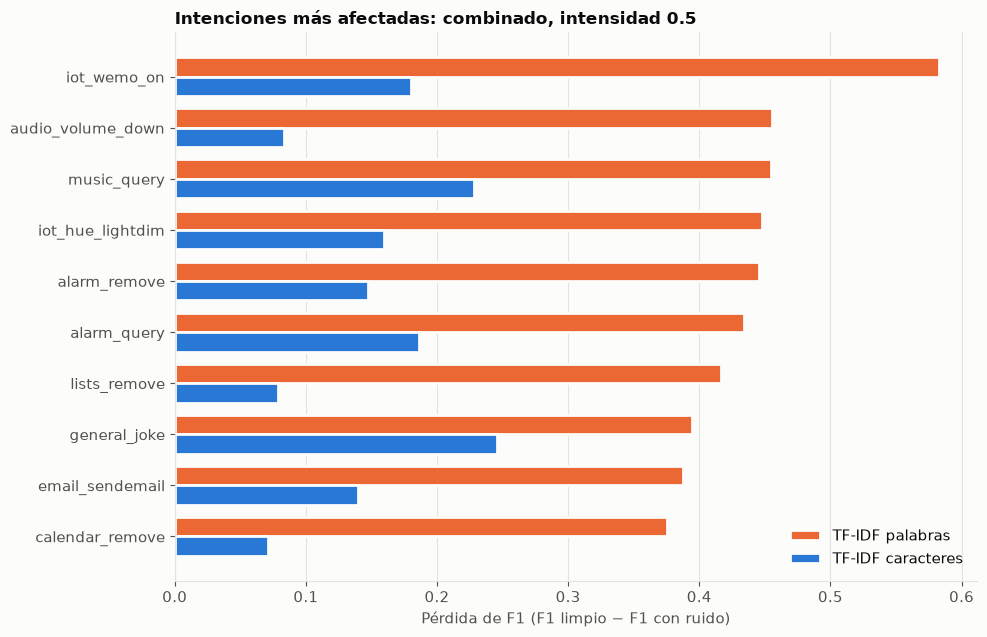

In [10]:
plots.plot_intent_drop(
    predictions,
    models=("tfidf_word", "tfidf_char"),
    perturbation="mixed",
    intensity=0.5,
);

## 4. Análisis de errores

Frases en las que un modelo acierta y el otro falla con la misma entrada perturbada.

In [11]:
def contrastar(acierta, falla, perturbation="typos", intensity=0.5, n=10, seed=0):
    sel = predictions.query(
        "split == 'validation' and perturbation == @perturbation"
        " and intensity == @intensity and seed == @SEED and train_seed == @SEED"
    )
    a = sel[sel["model"] == acierta].set_index("idx")
    b = sel[sel["model"] == falla].set_index("idx")
    mask = (a["pred"] == a["label"]) & (b["pred"] != b["label"])
    print(f"{mask.sum()} frases donde {acierta} acierta y {falla} falla")
    out = a.loc[mask, ["original", "text", "label"]].assign(
        **{f"pred_{falla}": b.loc[mask, "pred"]}
    )
    return out.sample(min(n, len(out)), random_state=seed)


contrastar("tfidf_char", "tfidf_word", "typos", 0.5)

438 frases donde tfidf_char acierta y tfidf_word falla


,original,text,label,pred_tfidf_word
idx,,,,
1052,borra cumpleaños de lucas del calendario,orra cumpleaños de luas del calendariio,calendar_remove,calendar_set
1662,cuantos años tiene pedro sánchez,cuntos añoos tiiene pedro sánchez,qa_factoid,news_query
1226,puedes crear una nueva lista,puedes crrear uha nueca listta,lists_createoradd,general_quirky
1490,dame direcciones para el lugar,dam direccciones para el lugar,transport_query,calendar_query
297,apaga mi lámpara de noche por favor,aapga mi lámpara de noche por favof,iot_hue_lightoff,general_quirky
85,puedes hacer mas brillante s las luces,puede hacer mas briilante s as lluces,iot_hue_lightup,general_quirky
792,borrar mi día de reuniones,borrrar mi díaa de reuniones,calendar_remove,calendar_query
1346,reproduce el podcast desde el principio,reprdouce el ppodcast dessde el prinfipio,play_podcasts,calendar_query
1305,incluir un elemento en una lista,incluir un elementto en ua oista,lists_createoradd,social_post


In [12]:
contrastar("tfidf_word", "tfidf_char", "typos", 0.5)

76 frases donde tfidf_word acierta y tfidf_char falla


,original,text,label,pred_tfidf_char
idx,,,,
1319,cancela la leche de la lista de la compra,cwncela la leche de la lista de la comra,lists_remove,lists_createoradd
1512,encuentra un taxi a xanadu,encentra un taix a xanadu,transport_taxi,general_quirky
509,cambia mi luz a otra aleatoria,cambia mi luz a ogra aleatoria,iot_hue_lightchange,music_settings
2024,publicar un correo electrónico al trabajador d...,publiar un correo elecrónico al trabajador de ...,email_sendemail,social_post
583,que semana es hoy,qe semsna es hyo,datetime_query,calendar_query
575,cuáles fueron los números ganadores del euromi...,cuuáles fueron los números ganadores del eurom...,news_query,qa_factoid
1902,enviar a ashmit sus últimos temas tecnológicos...,enviar a ashmmit sus últimos ttemas tecnológic...,email_sendemail,news_query
1388,olly indicame la posicion exacta de la tienda,olly nidicame la posicion exacta de la tieda,recommendation_locations,general_quirky
773,qué pasa en new york,qéu psaa en nnew york,recommendation_events,qa_factoid


In [13]:
contrastar("fasttext", "fasttext_word", "colloquial", 1.0)

201 frases donde fasttext acierta y fasttext_word falla


,original,text,label,pred_fasttext_word
idx,,,,
178,envíame una alerta sobre todos los nuevos tema...,envíame una alerta sobre todos los nuevos tema...,news_query,general_quirky
1903,hazme saver cuando laura me envíe un correo el...,hazme saver cuando laura me envíe un mail,email_query,general_joke
1238,cuáles fueron las últimas cinco listas que hice,cuáles fueron las últimas cinco listas que hice,lists_query,news_query
1118,que estaciones estan poniendo buena música est...,que estaciones estan poniendo buena música est...,play_radio,general_quirky
1931,paco vive en francia,paco vive en francia,email_querycontact,general_quirky
1956,abre mi cuenta de correo electrónico y revisa ...,abre mi cuenta de mail y revisa nuevos mails,email_query,social_query
61,pon mi canción favorita,pon mi tema favorita,play_music,play_radio
1663,necesito mantener a dos niños pequeños ocupado...,me hace falta mantener a dos niños pequeños oc...,general_quirky,calendar_query
136,convierte la hora de madrid en la hora de londres,convierte la hora de madrid en la hora de londres,datetime_convert,datetime_query


Confusiones más frecuentes de un modelo con una perturbación dada:

In [14]:
def confusiones(model, perturbation="mixed", intensity=0.5, top=10):
    sel = predictions.query(
        "split == 'validation' and model == @model"
        " and perturbation == @perturbation and intensity == @intensity"
        " and seed == @SEED and train_seed == @SEED"
    )
    err = sel[sel["label"] != sel["pred"]]
    return (
        err.groupby(["label", "pred"])
        .size()
        .sort_values(ascending=False)
        .head(top)
        .rename("errores")
    )


confusiones("tfidf_word")

label            pred          
play_music       general_quirky    21
weather_query    calendar_query    17
qa_factoid       general_quirky    15
email_query      general_quirky    14
calendar_set     calendar_query    14
weather_query    general_quirky    14
email_sendemail  general_quirky    14
play_podcasts    general_quirky    11
news_query       general_quirky    11
calendar_set     general_quirky    10
Name: errores, dtype: int64

### Confusión de base (sin ruido)

Antes de atribuirle errores al ruido hay que medir cuántos ya existían en la versión limpia. Las tablas juntan todas las semillas de ruido y de entrenamiento, así que los porcentajes son comparables entre modelos pero no son conteos de frases distintas. Para los pares se descartan las intenciones con menos de 8 frases en validation, donde una tasa de 100 % es solo ruido de muestra.

In [15]:
val = predictions.query("split == 'validation'").assign(
    ok=lambda d: d["pred"] == d["label"]
)
limpio = val.query("perturbation == 'clean'")

# Error sin ruido, y en cuántos pares real -> predicho se reparte.
pares = limpio.query("not ok").groupby(["model", "label", "pred"]).size()
pd.DataFrame(
    {
        "error sin ruido": 1 - limpio.groupby("model")["ok"].mean(),
        "pares distintos": pares.groupby("model").size(),
        "10 pares más frecuentes (% de los errores)": 100
        * pares.groupby("model").apply(lambda s: s.nlargest(10).sum() / s.sum()),
    }
).loc[models].rename(index=MODEL_LABELS)

,error sin ruido,pares distintos,10 pares más frecuentes (% de los errores)
model,,,
TF-IDF palabras,0.187,212,18.898
TF-IDF caracteres,0.158,191,19.938
FastText sin subpalabras,0.211,290,16.900
FastText con subpalabras,0.179,242,17.998
BETO,0.128,234,17.136


Pares real → predicho más confundidos sin ruido: fracción de las frases de la intención real que cada modelo predice como la otra. `general_quirky` funciona como sumidero.

In [16]:
# Pares más confundidos sin ruido: fracción de las frases de la intención real que se
# predicen como la otra, por modelo. Solo intenciones con 8 frases o más.
n_frases = limpio.query("model == 'tfidf_word'").groupby("label").size()
errores = limpio.query("not ok").groupby(["model", "label", "pred"]).size()
total = limpio.groupby(["model", "label"]).size()
tasa = (errores / total.reindex(errores.index.droplevel("pred")).to_numpy()).unstack(
    "model"
)
tasa = tasa.fillna(0)[models].loc[
    n_frases.reindex(tasa.index.get_level_values("label")).to_numpy() >= 8
]
tasa.assign(media=tasa.mean(axis=1)).sort_values("media", ascending=False).head(
    10
).rename(columns=MODEL_LABELS)

,model,TF-IDF palabras,TF-IDF caracteres,FastText sin subpalabras,FastText con subpalabras,BETO,media
label,pred,,,,,,
music_settings,play_music,0.375,0.250,0.375,0.375,0.250,0.325
recommendation_movies,general_quirky,0.417,0.333,0.250,0.250,0.083,0.267
datetime_convert,datetime_query,0.333,0.333,0.444,0.000,0.111,0.244
qa_maths,qa_factoid,0.308,0.231,0.154,0.154,0.231,0.215
social_query,news_query,0.222,0.167,0.111,0.111,0.093,0.141
iot_hue_lightdim,iot_hue_lightoff,0.176,0.118,0.176,0.059,0.098,0.125
qa_factoid,general_quirky,0.122,0.122,0.163,0.141,0.059,0.121
music_likeness,music_query,0.188,0.062,0.125,0.188,0.021,0.117
audio_volume_down,qa_factoid,0.125,0.250,0.000,0.208,0.000,0.117


De los errores con ruido, qué fracción ya era error en la versión limpia de la misma frase (mismo modelo y misma semilla de entrenamiento). El resto son errores causados por el ruido. Con intensidad baja, buena parte de los errores no es del ruido: por eso se mide la caída respecto de la versión limpia.

In [17]:
base = limpio[["model", "train_seed", "idx", "ok"]].rename(columns={"ok": "ok_limpio"})


def errores_previos(perturbation, intensity):
    """Fracción de los errores con ruido que ya eran errores sin ruido, por modelo."""
    err = val.query(
        "perturbation == @perturbation and intensity == @intensity and not ok"
    ).merge(base, on=["model", "train_seed", "idx"])
    return 100 * (~err["ok_limpio"]).groupby(err["model"]).mean()


casos = [("typos", 0.25), ("typos", 1.0), ("no_accents", 0.25), ("colloquial", 0.25)]
pd.DataFrame({f"{p} {i:g}": errores_previos(p, i) for p, i in casos}).loc[
    models
].rename(index=MODEL_LABELS)

,typos 0.25,typos 1,no_accents 0.25,colloquial 0.25
model,,,,
TF-IDF palabras,58.919,19.234,94.920,95.516
TF-IDF caracteres,75.038,39.839,96.580,95.629
FastText sin subpalabras,57.242,20.891,94.367,94.463
FastText con subpalabras,69.738,36.558,95.969,96.317
BETO,52.457,16.215,96.359,97.841


## 5. Comparación con LLM locales

Pedido opcional de la devolución del docente: ¿un LLM chico sin entrenar es más robusto al ruido, y a qué costo? Se probaron `llama3.1` (8B) y `qwen3.5:4b` con Ollama, con dos ejemplos por intención en el prompt (k=2). El prompt se eligió sobre test (500 frases limpias) y la robustez se mide sobre validation, igual que con los demás modelos.

Para regenerar las tablas y la figura hay que haber corrido `llm.py`, `latencia.py` y `comparacion.py` (ver `GUIA.md`, §8).

Advertencias: los LLM se evaluaron con **una** semilla de ruido y solo en las intensidades 0,25 y 1,0 (por eso su línea en la figura es una recta entre puntos medidos). La latencia del LLM incluye servidor y HTTP, la de los demás no: la comparación es de orden de magnitud.

In [18]:
comparacion = pd.read_csv(RESULTS_DIR / "comparacion.csv")
comparacion.rename(
    columns={
        "model": "modelo",
        "p50_ms": "p50 (ms)",
        "frases_por_s": "frases/s (lote)",
        "wh_por_1000": "Wh / 1000 frases",
    }
).round(3)

,modelo,limpio,"typos 0,25","typos 1,0","combinado 1,0","caída typos 1,0",p50 (ms),frases/s (lote),Wh / 1000 frases
0,TF-IDF palabras,"0.813 [0.794, 0.829]","0.710 [0.695, 0.726]","0.132 [0.119, 0.145]","0.122 [0.109, 0.136]",0.681,0.496,38288.663,NaN
1,TF-IDF caracteres,"0.842 [0.826, 0.857]","0.804 [0.788, 0.818]","0.647 [0.630, 0.662]","0.539 [0.523, 0.555]",0.195,0.538,26372.570,NaN
2,FastText sin subpalabras,"0.789 [0.772, 0.807]","0.668 [0.652, 0.684]","0.102 [0.090, 0.115]","0.108 [0.095, 0.120]",0.687,0.008,40853.347,NaN
3,FastText con subpalabras,"0.821 [0.805, 0.838]","0.768 [0.752, 0.782]","0.582 [0.567, 0.598]","0.489 [0.473, 0.504]",0.239,0.012,33973.968,NaN
4,BETO,"0.872 [0.858, 0.885]","0.775 [0.762, 0.788]","0.298 [0.285, 0.310]","0.273 [0.262, 0.285]",0.574,6.249,3046.571,0.017
5,llama3.1 (k=2),"0.670 [0.650, 0.690]","0.627 [0.606, 0.648]","0.470 [0.449, 0.490]","0.412 [0.390, 0.432]",0.201,569.195,7.003,12.696
6,qwen3.5:4b (k=2),"0.730 [0.711, 0.748]","0.694 [0.675, 0.713]","0.554 [0.534, 0.577]","0.494 [0.472, 0.515]",0.176,1062.222,3.773,21.023


Accuracy en validation con IC 95 % (bootstrap sobre frases). Los Wh de TF-IDF y FastText están vacíos a propósito: corren en CPU y `nvidia-smi` solo mediría la GPU en reposo.

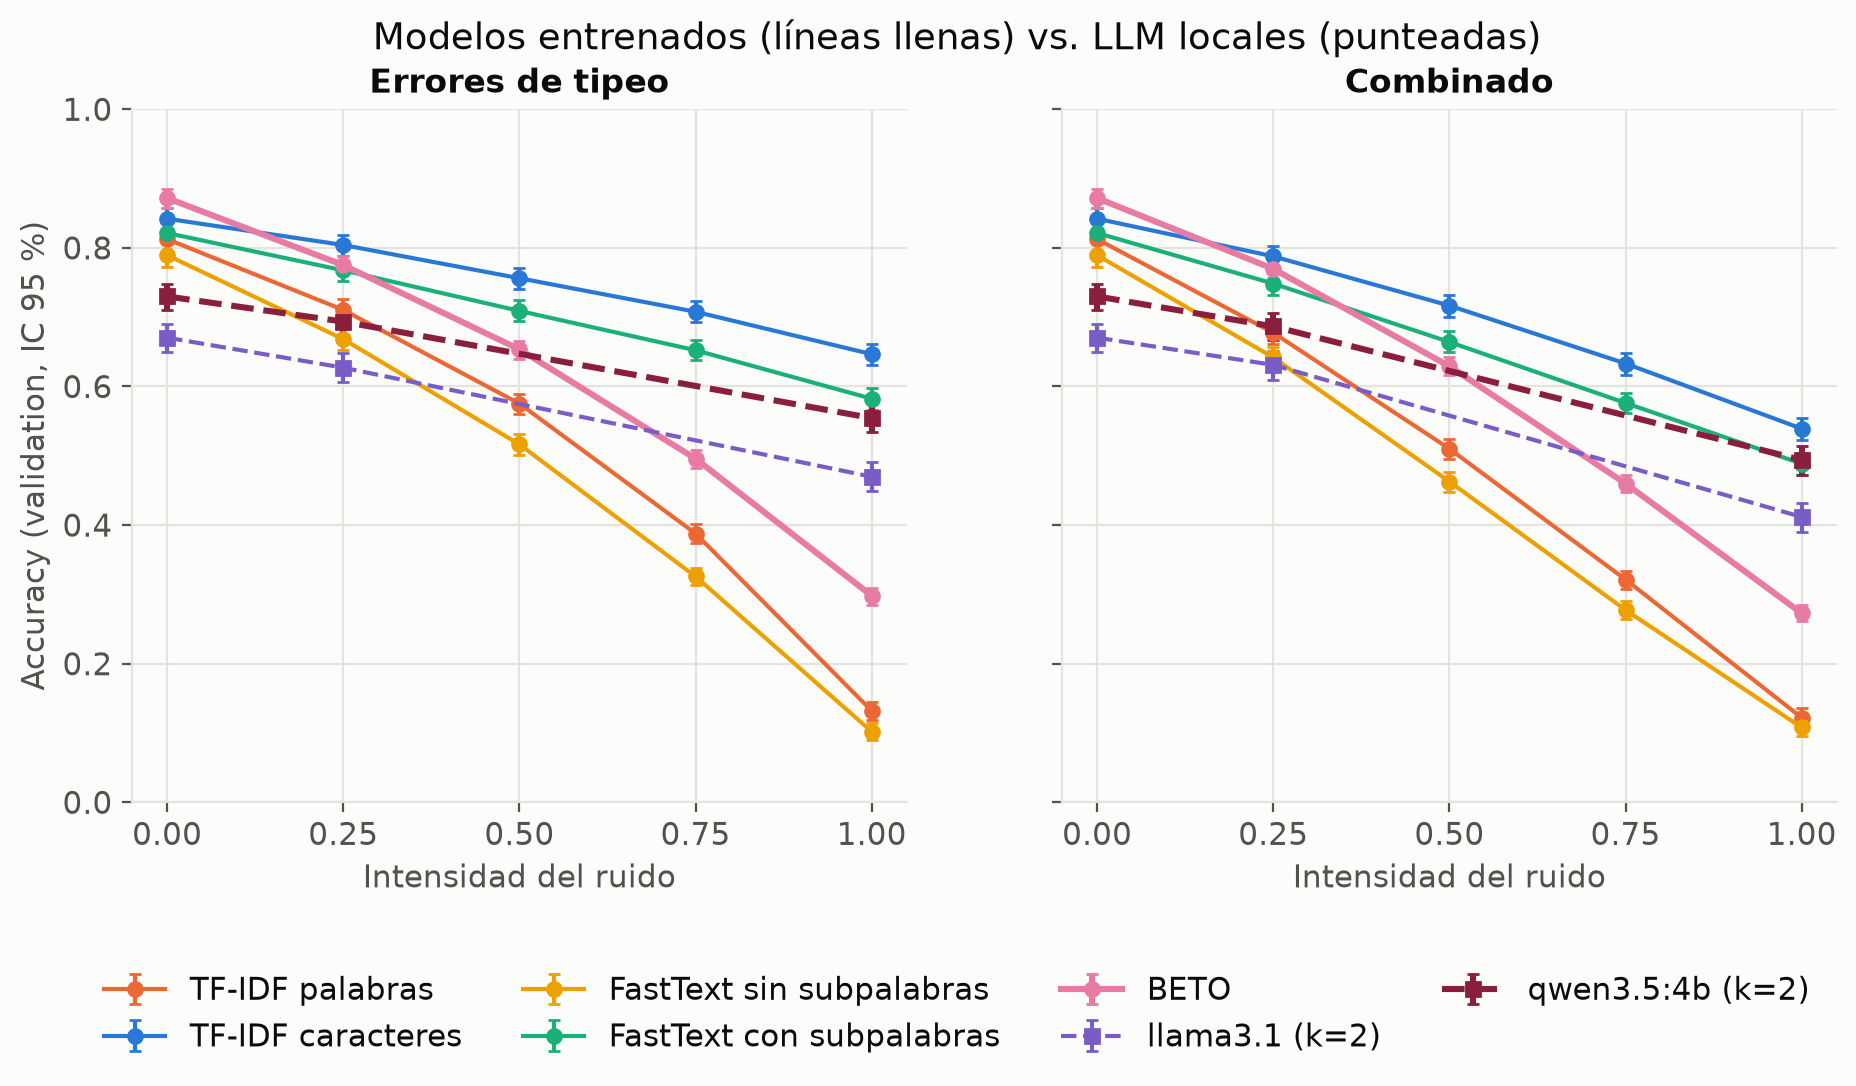

In [19]:
from IPython.display import Image

Image(filename=plots.FIGURES_DIR / "6_cruce_llm.png")

Lectura: ningún LLM supera a TF-IDF de caracteres en ninguna intensidad; contra BETO sí hay un cruce con typos intensos (BETO arranca arriba y termina por debajo). Con k=0 el LLM cae más que con k=2 ante typos, aunque sin ruido rinden casi igual: los ejemplos del prompt ayudan a la robustez más que al nivel base.

## 6. Probar frases propias

Carga los modelos entrenados y muestra la predicción de cada uno para la frase original y sus versiones con ruido.

In [20]:
from tp.models import MODELS, cache_path

# Modelos entrenados con la semilla principal.
cargados = {}
for m in models:
    model = MODELS[m]()
    cargados[m] = model.load(cache_path(m, model))


def probar(frase, intensity=0.5):
    variantes = {"Original": frase} | {
        PERTURBATION_LABELS[n]: perturb([frase], n, intensity)[0] for n in PERTURBATIONS
    }
    textos = list(variantes.values())
    tabla = pd.DataFrame({"texto": textos}, index=list(variantes))
    for m, model in cargados.items():
        tabla[MODEL_LABELS[m]] = model.predict(textos)
    return tabla


probar("ponme una alarma para mañana a las siete por favor")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 11189.56it/s]

,texto,TF-IDF palabras,TF-IDF caracteres,FastText sin subpalabras,FastText con subpalabras,BETO
Original,ponme una alarma para mañana a las siete por f...,alarm_set,alarm_set,alarm_set,alarm_set,alarm_set
Sin tildes,ponme una alarma para mañana a las siete por f...,alarm_set,alarm_set,alarm_set,alarm_set,alarm_set
Minúsculas y sin puntuación,ponme una alarma para mañana a las siete por f...,alarm_set,alarm_set,alarm_set,alarm_set,alarm_set
Errores de tipeo,ponme uja alarma para mañana a lax siete por faor,alarm_set,alarm_set,alarm_set,alarm_set,alarm_set
Abreviaturas,ponme una alarma pa mñn a las 7 xfa,alarm_set,alarm_set,alarm_set,alarm_set,alarm_set
Voseo rioplatense,poneme una alarma para mañana a las siete por ...,alarm_set,alarm_set,alarm_set,alarm_set,alarm_set
Vocabulario coloquial,ponme una alarma para mañana a las siete por f...,alarm_set,alarm_set,alarm_set,alarm_set,alarm_set
Combinado,ponme uuna alarma para mñn a las siete por favor,alarm_set,alarm_set,alarm_set,alarm_set,alarm_set


In [21]:
probar("envía un correo electrónico a mi jefe diciendo que llego tarde", intensity=1.0)

,texto,TF-IDF palabras,TF-IDF caracteres,FastText sin subpalabras,FastText con subpalabras,BETO
Original,envía un correo electrónico a mi jefe diciendo...,email_sendemail,email_sendemail,email_sendemail,email_sendemail,email_sendemail
Sin tildes,envia un correo electronico a mi jefe diciendo...,email_sendemail,email_sendemail,email_sendemail,email_sendemail,email_sendemail
Minúsculas y sin puntuación,envía un correo electrónico a mi jefe diciendo...,email_sendemail,email_sendemail,email_sendemail,email_sendemail,email_sendemail
Errores de tipeo,ejvía un corrreo electróinco a mi jfe diciedno...,social_post,email_sendemail,general_quirky,email_sendemail,social_post
Abreviaturas,envía un correo electrónico a mi jefe diciendo...,email_sendemail,email_sendemail,email_sendemail,email_sendemail,email_sendemail
Voseo rioplatense,mandá un correo electrónico a mi jefe diciendo...,email_sendemail,email_sendemail,email_sendemail,email_sendemail,email_sendemail
Vocabulario coloquial,envía un mail a mi jefe diciendo que llego tarde,email_sendemail,email_sendemail,email_sendemail,email_sendemail,email_sendemail
Combinado,mqnda un maiil a mi jfee diciedno q lleggo tarse,social_post,general_quirky,general_quirky,email_sendemail,email_querycontact
